# Tools - flow in networks III
This notebook presents some tools related to (laminar) flow in a graph (network):
- solving flow problem with boundary conditions (additional example)
- illustration of flow in series and flow in parallel

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Flow equations 
See notebook `H1-Flow-in-networks-I.ipynb` and notebook `H2-Flow-in-networks-II.ipynb` for flow equations with boundary conditions.


In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a small graph in 2D
A 2D example - a graph generated from a Delaunay triangulation of points.

In [5]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

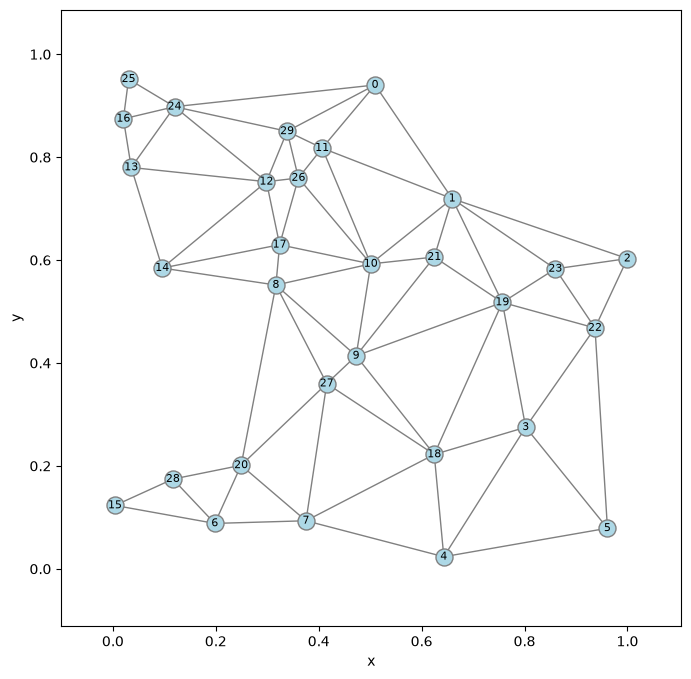

In [6]:
# Number of points and seed
npoints = 30
seed = 35306

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points,
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points,min_edge_len=0.01, max_edge_len=0.4)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

- Add a node with a string as label to check that the developed algorithms work property

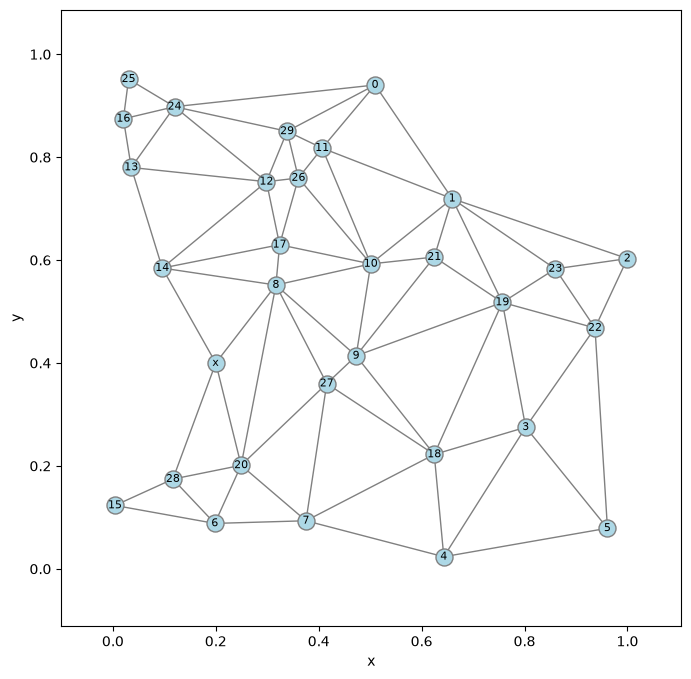

In [7]:
# Add a node with label 'x' and some edges
g.add_node('x')
g.nodes['x']['pos'] = np.array([0.2, 0.4])
g.add_edges_from([('x', i) for i in [8, 14, 28, 20]])

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [8]:
# Set edge weight (w) (conductance)
# ---------------------------------
# # Uniform (constant)
# w = {e: 1.0 for e in g.edges()} # unweigted graph (specifying argument edge_weight=None in the functions below)

# # Set random conductance on edges - U([0, 1])
# np.random.seed(1211)
# w_arr = np.random.rand(len(g.edges()))
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Set random conductance on edges - lognormal, log weight ~ N(m, s^2)
# np.random.seed(353)
# m = 0.0
# s = 1.0
# w_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(g.number_of_edges())) # random values in log-normal distribution
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# Inverse of edge length
w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

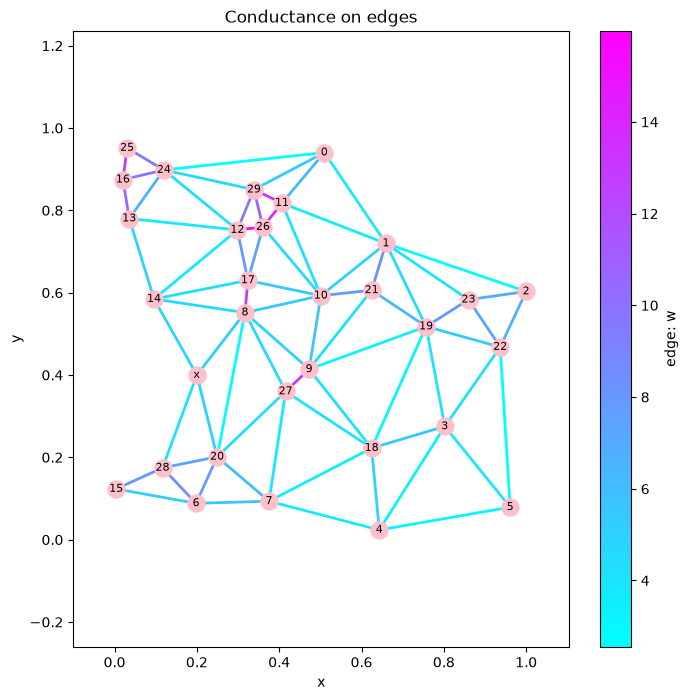

In [9]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Plot conductances - edge width proportional to conductance

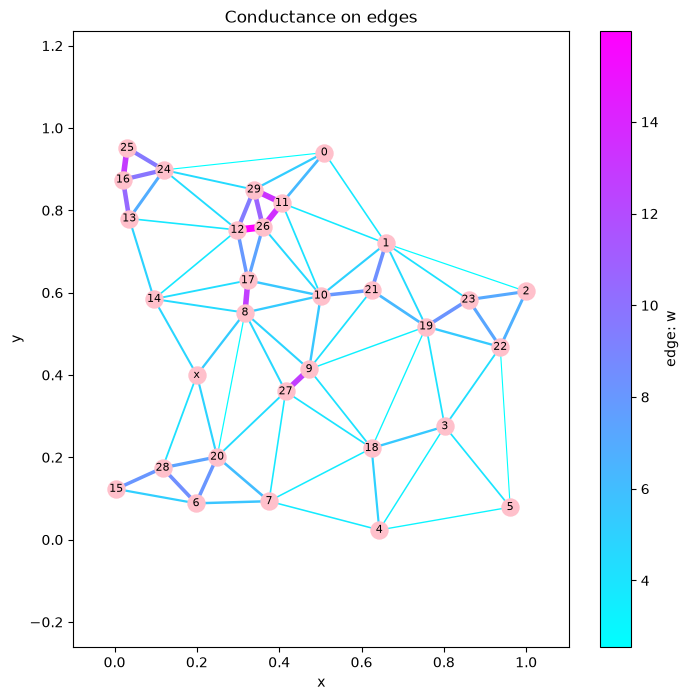

In [10]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')
plt.show()

## Flow in the network with boundary condition
Boundary nodes:
- $\mathcal{B}$, with $p(u) = 0.0$ for $u\in\mathcal{B}$, nodes at the right of the domain

Inner nodes:
- $\mathcal{I}= V\setminus \mathcal{B} \supset \mathcal{F}$, with 
    - $q(u)$ = 1.0 for $u\in\mathcal{F}$, nodes at the left of the domain
    - $q(u)$ = 0.0 for $u\in\mathcal{I}\setminus\mathcal{F}$


In [11]:
# Boundary nodes label
B_nodes_label = [2, 22, 5] 

# Potential at boundary nodes
pB_nodes_dict = {u: 0.0 for u in B_nodes_label}

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pB_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

F_nodes_label = [25, 16, 13, 14, 'x', 28, 15]
for u in F_nodes_label:
    qI_nodes_dict[u] = 1.0

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pB_nodes_dict=pB_nodes_dict, 
                                qI_nodes_dict=qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)

# Set node potential as node attribute in graph `g`
nx.set_node_attributes(g, p_nodes_dict, 'potential')

# Add entering flux as node attribute 'entering_flux'
nx.set_node_attributes(g, q_nodes_dict, 'entering_flux')

# Absolute flows along edges
# --------------------------
# Compute absolute flows along edges
edge_abs_flow_dict = kn.tools.compute_abs_flow_along_edges(g, edge_weight='w', node_potential='potential')

# Set absolute flow as edge attribute in graph `g`
nx.set_edge_attributes(g, edge_abs_flow_dict, 'q_abs')

# Flows along edges - directed graph
# ----------------------------------
g_dir = kn.tools.compute_directed_graph_of_flow(g, edge_weight='w', node_potential='potential', edge_flow='q')
# -> directed graph with flow as edge attributes - only the edges with positive (or zero) flow are kept

### Do some checks

In [12]:
# Check local equation on each edge
ok = np.allclose(
    [g.edges[u, v]['q_abs'] - g.edges[u, v]['w'] * np.abs(g.nodes[u]['potential'] - g.nodes[v]['potential'])
        for u, v in g.edges()], 
    0)
print(f'Local equations ok ? {ok}')


Local equations ok ? True


In [13]:
# Check:
# - flux = 0 along edges linking 2 nodes in B_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B_nodes_label:
    for v in B_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


edge: 2 ~ 22, flux: 0
edge: 5 ~ 22, flux: 0


In [14]:
# Check entering flux on boundary nodes
d = nx.get_node_attributes(g, 'entering_flux')

for u in B_nodes_label:
    print(f'node: {u}, entering flux: {d[u]}')  

print()    

s = np.sum(list(d.values()))
print(f'sum of entering fluxes: {s:.4g}')
print(f'sum of entering fluxes close to zero ? {np.isclose(s, 0)}')


node: 2, entering flux: -2.0640149427414523
node: 22, entering flux: -3.234649002672314
node: 5, entering flux: -1.7013360545862206

sum of entering fluxes: 1.332e-14
sum of entering fluxes close to zero ? True


### Plot result (1) - undirected graph
Plot node potential and absolute edge flow.

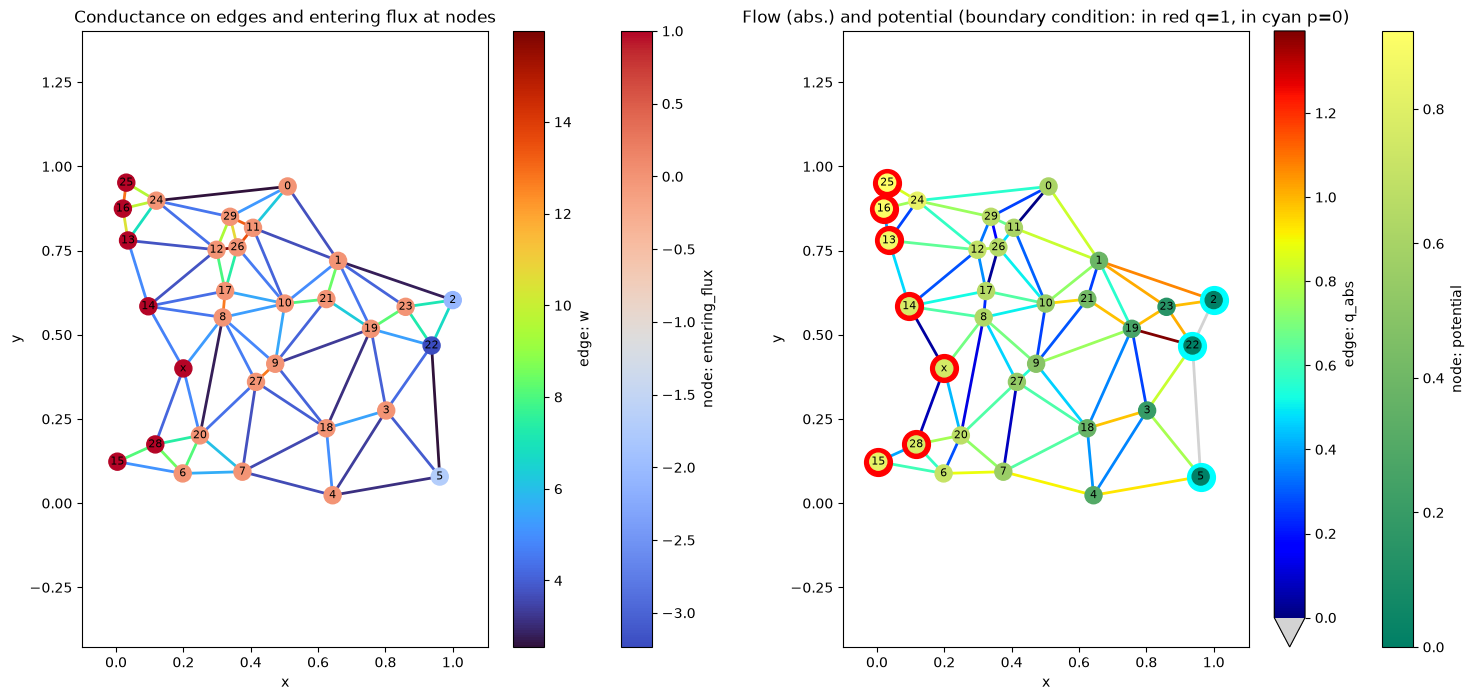

In [15]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'extend':'min'},
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in F_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red q=1, in cyan p=0)')

plt.show()


### Plot results (2) - directed graph

Plot node potential and oriented edge flow.

*Note. With directed graph, the color bar can not be displayed, because the function `nx.draw_networkx_edges` does not return any "mappable" required for plotting color bar. To display the color bar, one can first employ the undirected graph with absolute values of flow on edges, and then utilize the directed graph to show the oriented edges (see below).*

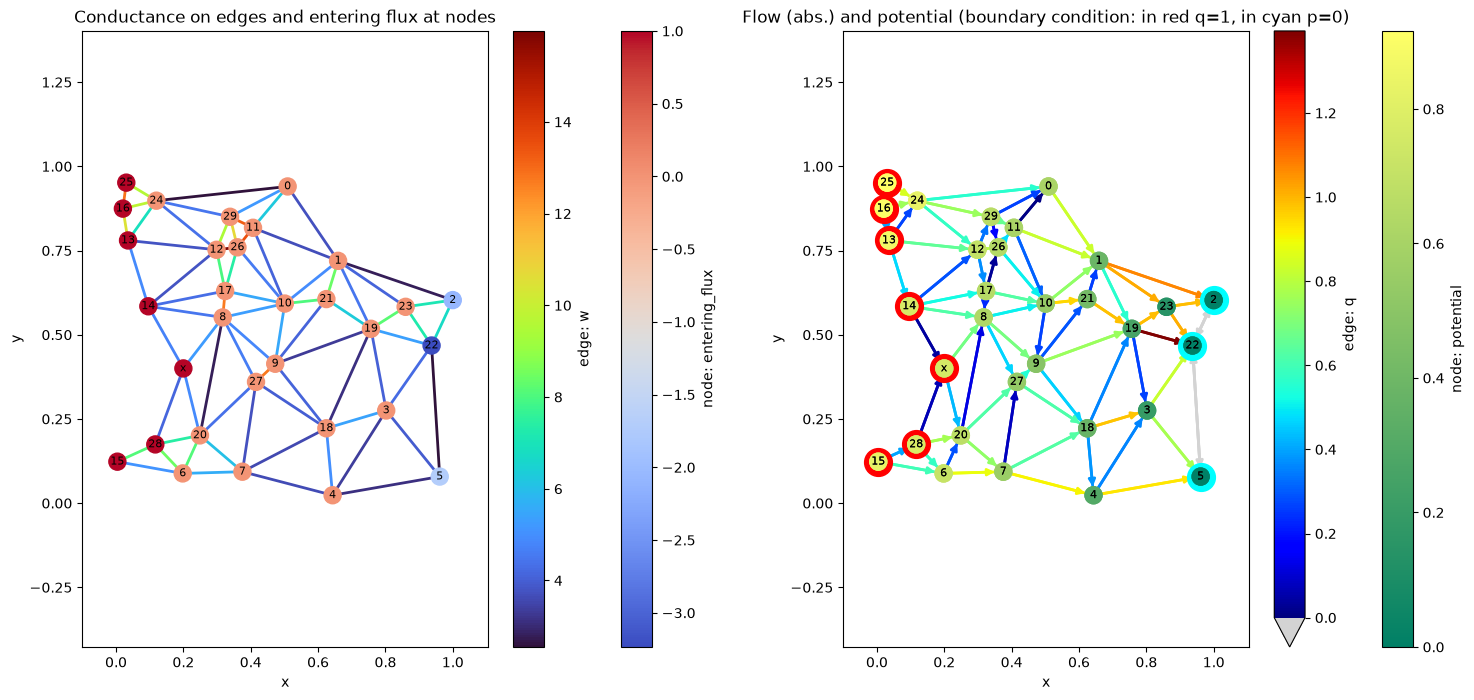

In [16]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ----
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# ----------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in F_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red q=1, in cyan p=0)')

plt.show()


### Plot results (3) - directed graph - custom
Plot node potential and oriented edge flow ; set edge width according to values and add edge labels.

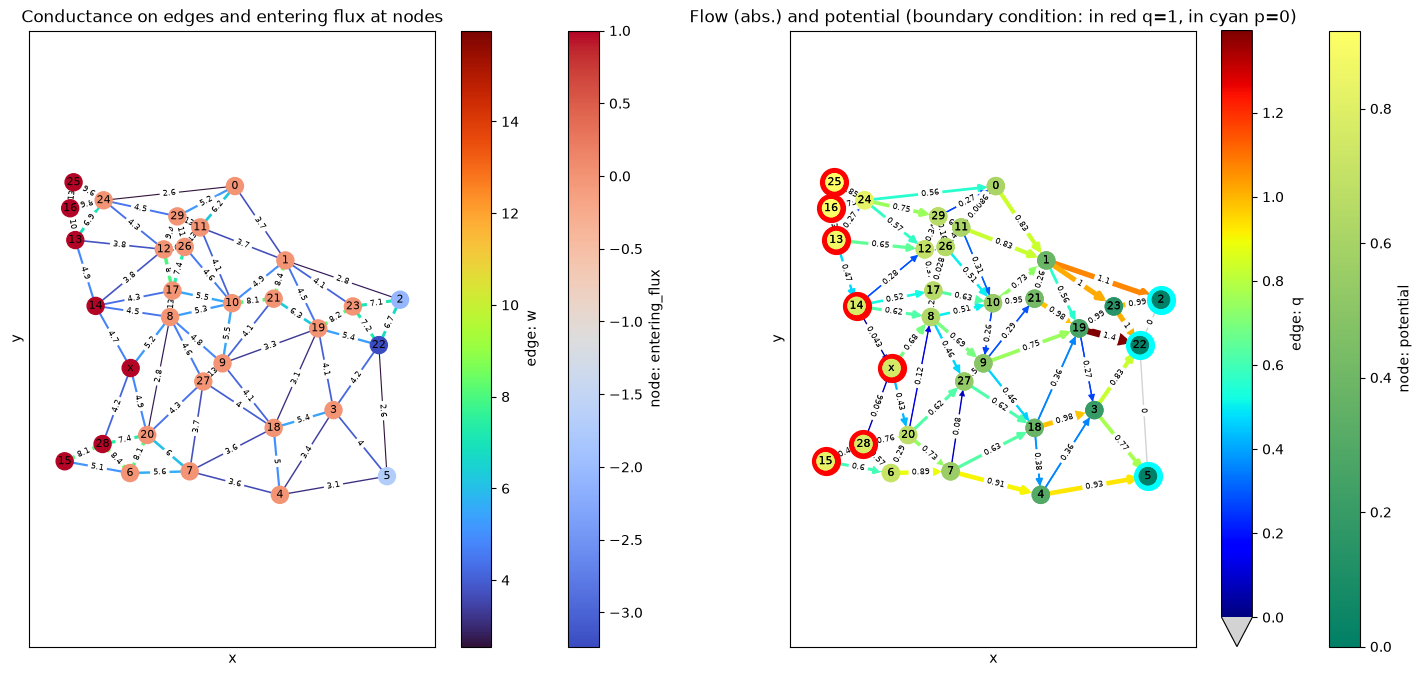

In [17]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

q = np.abs(np.asarray(list(nx.get_edge_attributes(g_dir, 'q').values())))
q_width_max = 5
q_width = q/q.max() * q_width_max

# Node position
pos = nx.get_node_attributes(g, 'pos')

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    width = w_width, # set edge  width
    **options)

# ... add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'w').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    width = q_width, # set edge  width
    **options)

# ...add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'q_abs').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in F_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red q=1, in cyan p=0)')

plt.show()


## Illustration of flow in series and flow in parallel

## Flow in series

In [18]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

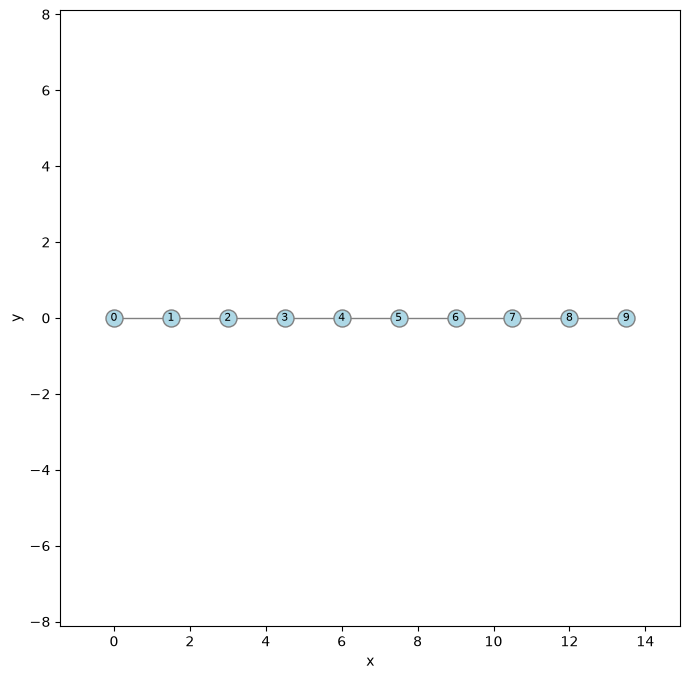

In [19]:
# Number of points
npoints = 10

# Generate 1D grid graph
g = kn.misc.graph_grid(dimension=npoints, spacing=1.5)

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [20]:
# Set edge weight (w) (conductance)
# ---------------------------------
# # Uniform (constant)
# w = {e: 1.0 for e in g.edges()} # unweigted graph (specifying argument edge_weight=None in the functions below)

# Set random conductance on edges - U([0, 1])
np.random.seed(1211)
w_arr = np.random.rand(len(g.edges()))
w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Set random conductance on edges - lognormal, log weight ~ N(m, s^2)
# np.random.seed(353)
# m = 0.0
# s = 1.0
# w_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(g.number_of_edges())) # random values in log-normal distribution
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Inverse of edge length
# w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# # w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

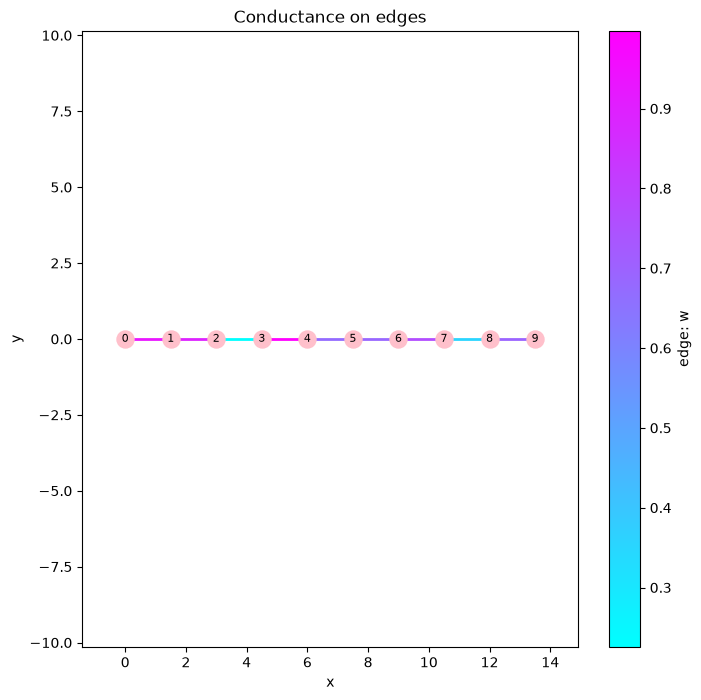

In [21]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Plot conductances - edge width proportional to conductance

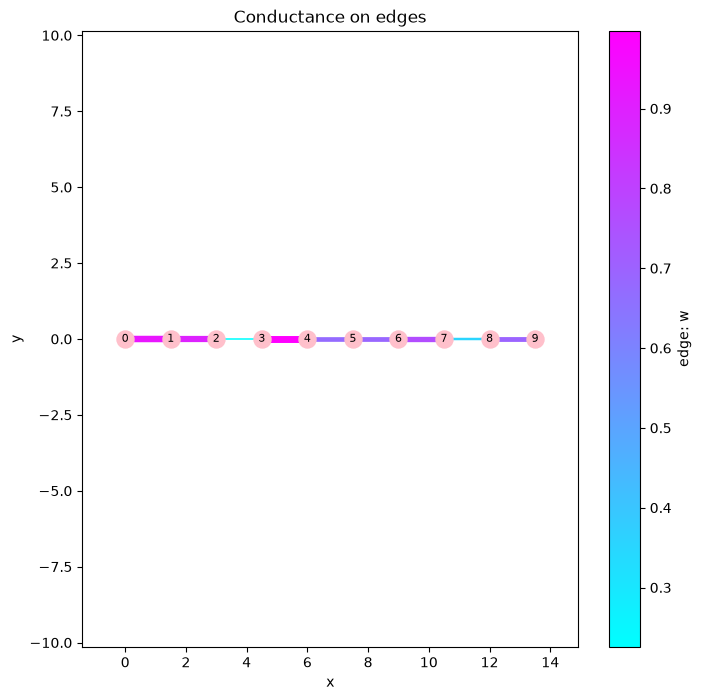

In [22]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')
plt.show()

## Flow in the network with boundary condition
Boundary nodes:
- $\mathcal{B} = \mathcal{B}_1 \sqcup \mathcal{B}_2$, with 
    - $p(u) = 1.0$ for $u\in\mathcal{B}_1$, node at the left of the domain
    - $p(u) = 0.0$ for $u\in\mathcal{B}_2$, node at the right of the domain

Inner nodes:
- $\mathcal{I}= V\setminus \mathcal{B}$, with $q(u)$ = 0 for $u\in\mathcal{I}$.


In [23]:
# Boundary nodes label
B1_nodes_label = [0] 
B2_nodes_label = [g.number_of_nodes()-1] 
# B_nodes_label = B1_nodes_label + B2_nodes_label

# Potential at boundary nodes
pB1_nodes_dict = {u: 1.0 for u in B1_nodes_label}
pB2_nodes_dict = {u: 0.0 for u in B2_nodes_label}
# - merge dictionaries
pB_nodes_dict = pB1_nodes_dict
pB_nodes_dict.update(pB2_nodes_dict)

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pB_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pB_nodes_dict=pB_nodes_dict, 
                                qI_nodes_dict=qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)

# Set node potential as node attribute in graph `g`
nx.set_node_attributes(g, p_nodes_dict, 'potential')

# Add entering flux as node attribute 'entering_flux'
nx.set_node_attributes(g, q_nodes_dict, 'entering_flux')

# Absolute flows along edges
# --------------------------
# Compute absolute flows along edges
edge_abs_flow_dict = kn.tools.compute_abs_flow_along_edges(g, edge_weight='w', node_potential='potential')

# Set absolute flow as edge attribute in graph `g`
nx.set_edge_attributes(g, edge_abs_flow_dict, 'q_abs')

# Flows along edges - directed graph
# ----------------------------------
g_dir = kn.tools.compute_directed_graph_of_flow(g, edge_weight='w', node_potential='potential', edge_flow='q')
# -> directed graph with flow as edge attributes - only the edges with positive (or zero) flow are kept

### Do some checks

In [24]:
# Check local equation on each edge
ok = np.allclose(
    [g.edges[u, v]['q_abs'] - g.edges[u, v]['w'] * np.abs(g.nodes[u]['potential'] - g.nodes[v]['potential'])
        for u, v in g.edges()], 
    0)
print(f'Local equations ok ? {ok}')


Local equations ok ? True


In [25]:
# Check:
# - flux = 0 along edges linking 2 nodes in B1_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B1_nodes_label:
    for v in B1_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


In [26]:
# Check:
# - flux = 0 along edges linking 2 nodes in B2_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B2_nodes_label:
    for v in B2_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


In [27]:
# Check entering flux on boundary nodes
d = nx.get_node_attributes(g, 'entering_flux')

for u in B1_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

for u in B2_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

s = np.sum(list(d.values()))
print(f'sum of entering fluxes: {s:.4g}')
print(f'sum of entering fluxes close to zero ? {np.isclose(s, 0)}')


node: 0, entering flux: 0.0619

node: 9, entering flux: -0.0619

sum of entering fluxes: 1.11e-16
sum of entering fluxes close to zero ? True


### Plot result (1) - undirected graph
Plot node potential and absolute edge flow.

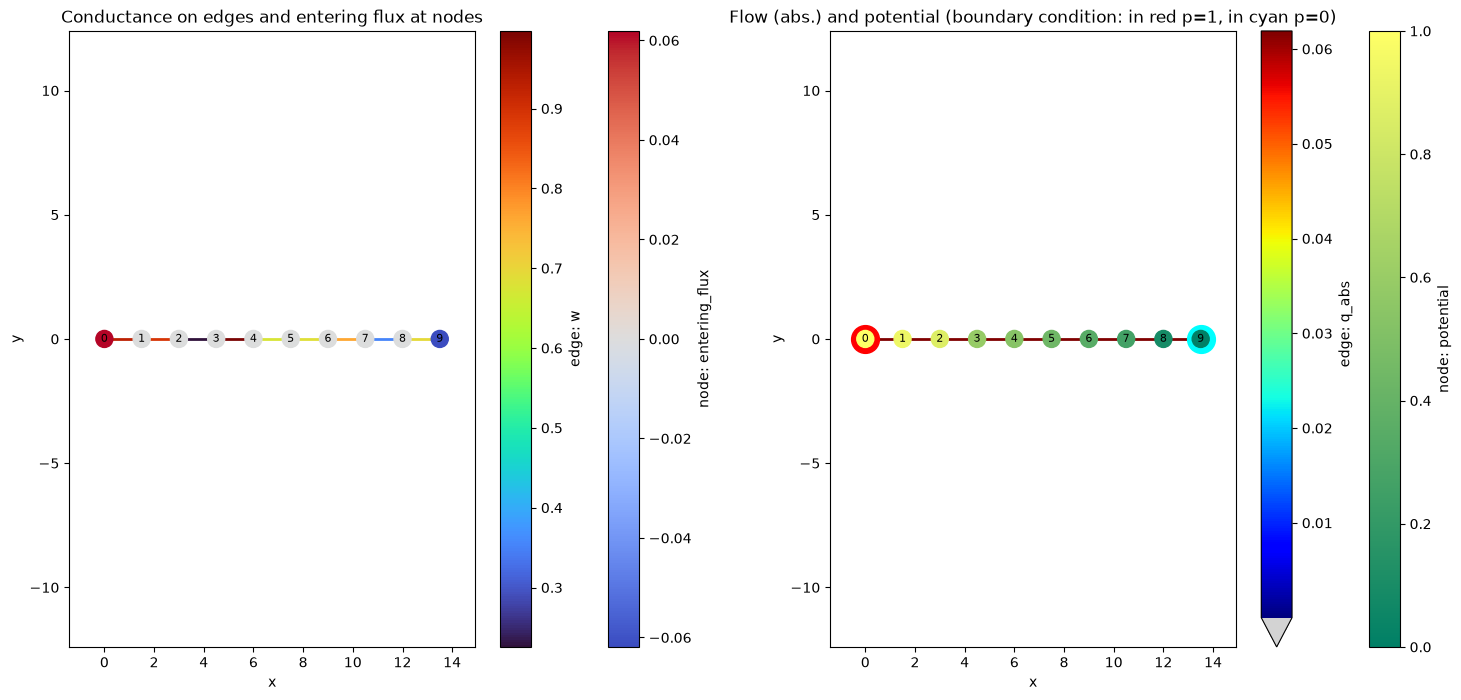

In [28]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'extend':'min'},
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


### Plot results (2) - directed graph

Plot node potential and oriented edge flow.

*Note. With directed graph, the color bar can not be displayed, because the function `nx.draw_networkx_edges` does not return any "mappable" required for plotting color bar. To display the color bar, one can first employ the undirected graph with absolute values of flow on edges, and then utilize the directed graph to show the oriented edges (see below).*

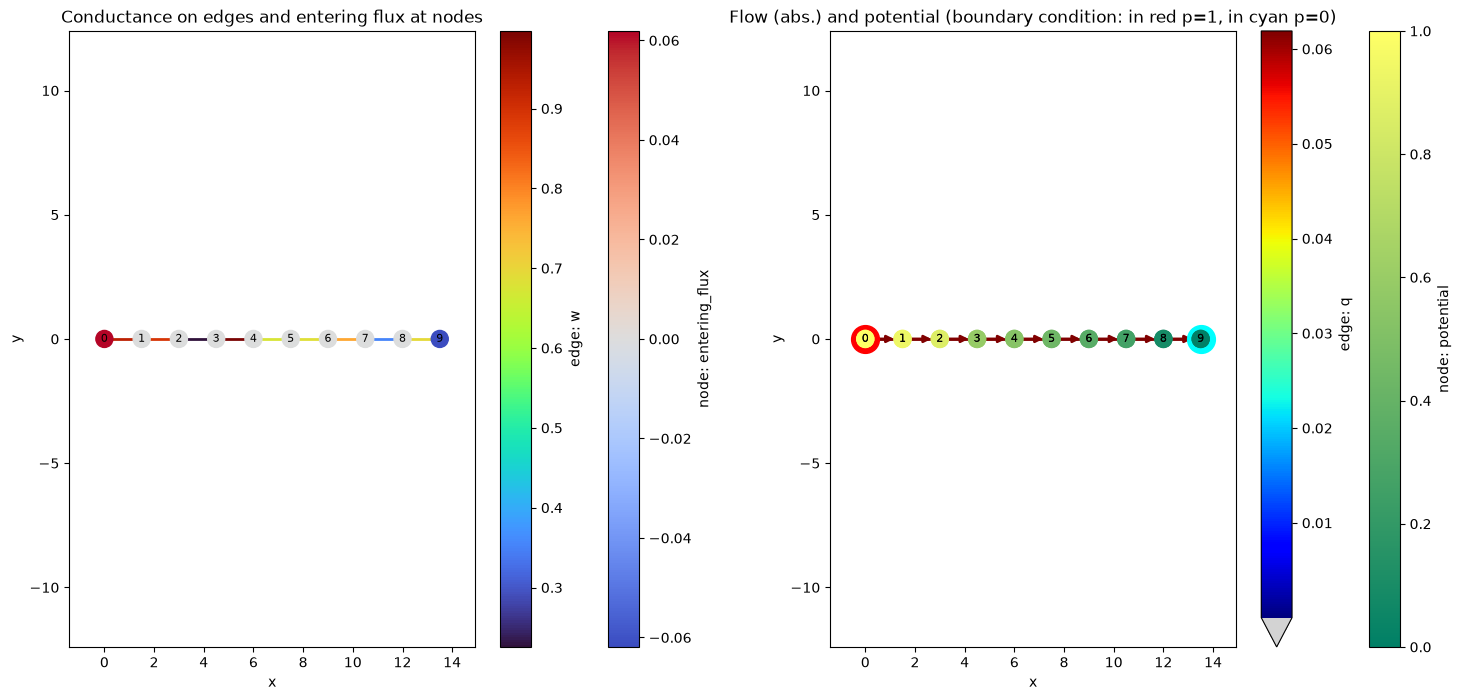

In [29]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ----
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# ----------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')
plt.show()


### Plot results (3) - directed graph - custom
Plot node potential and oriented edge flow ; set edge width according to values and add edge labels.

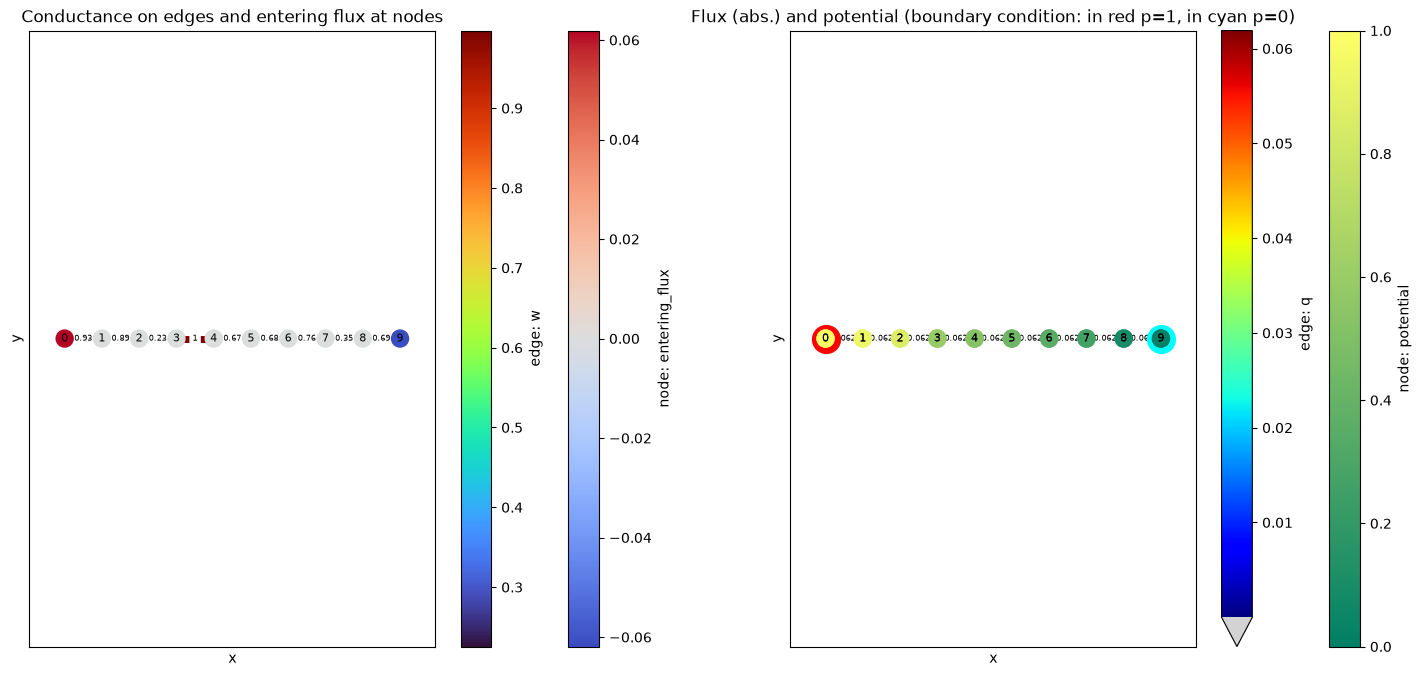

In [30]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

q = np.abs(np.asarray(list(nx.get_edge_attributes(g_dir, 'q').values())))
q_width_max = 5
q_width = q/q.max() * q_width_max

# Node position
pos = nx.get_node_attributes(g, 'pos')

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    width = w_width, # set edge  width
    **options)

# ... add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'w').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    width = q_width, # set edge  width
    **options)

# ...add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'q_abs').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flux (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


### Upscale the conductances in series

In [31]:
# Upscale the conductances
u0 = 0
u1 = g.number_of_nodes() - 1
T_eq_1 = kn.tools.equivalent_conductance(g, [(u0, u1)], edge_weight='w')[0]
T_eq_2 = 1./np.sum([1.0/g[u][v]['w'] for u, v in g.edges()])
print(f'Equivalent conductance in series is the inverse of the sum of the inverse of the single conductances : {np.isclose(T_eq_1, T_eq_2)}')


Equivalent conductance in series is the inverse of the sum of the inverse of the single conductances : True


## Flow in parallel

In [32]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

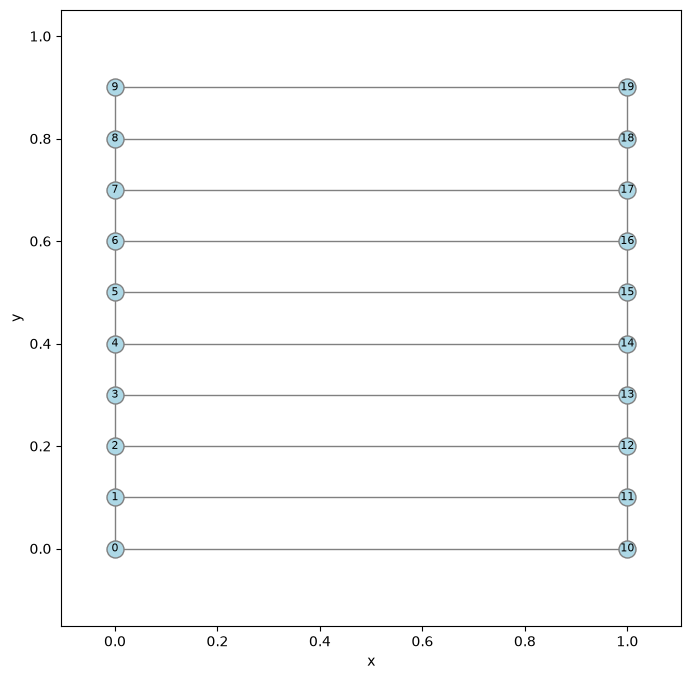

In [33]:
# Number of points
n = 10

# Generate 2D grid graph
g = kn.misc.graph_grid(dimension=(2, n), spacing=(1, 1./n))

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

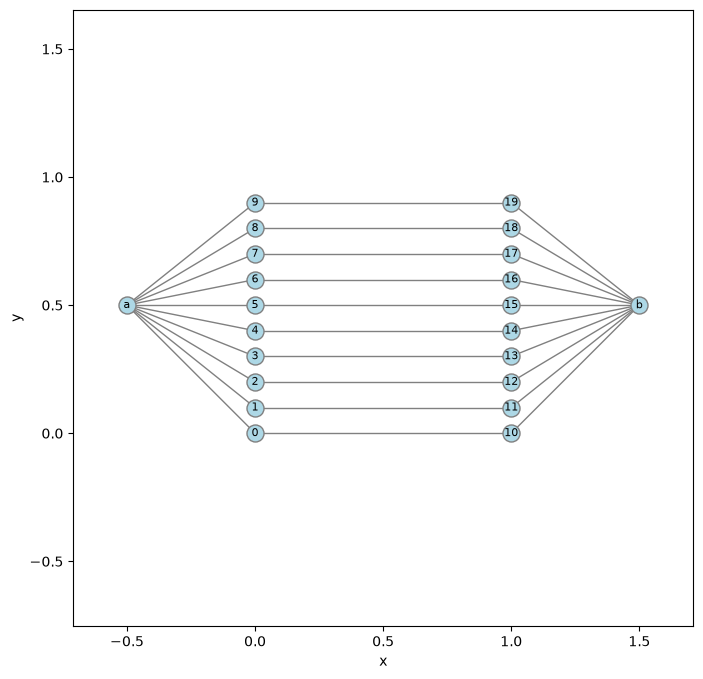

In [34]:
g.remove_edges_from(np.vstack([[[i, i+1], [n+i, n+i+1]] for i in range(n-1)]))
g.add_nodes_from(['a', 'b'])
g.nodes['a']['pos'] = np.array([-0.5, 0.5])
g.nodes['b']['pos'] = np.array([1.5, 0.5])
for i in range(n):
    g.add_edge('a', i)
    g.add_edge(n+i, 'b')

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [35]:
# Set edge weight (w) (conductance)
# ---------------------------------
# # Uniform (constant)
# w = {e: 1.0 for e in g.edges()} # unweigted graph (specifying argument edge_weight=None in the functions below)

# Set random conductance on edges - U([0, 1])
np.random.seed(121)
w_arr = np.random.rand(len(g.edges()))
w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Set random conductance on edges - lognormal, log weight ~ N(m, s^2)
# np.random.seed(353)
# m = 0.0
# s = 1.0
# w_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(g.number_of_edges())) # random values in log-normal distribution
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Inverse of edge length
# w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# # w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

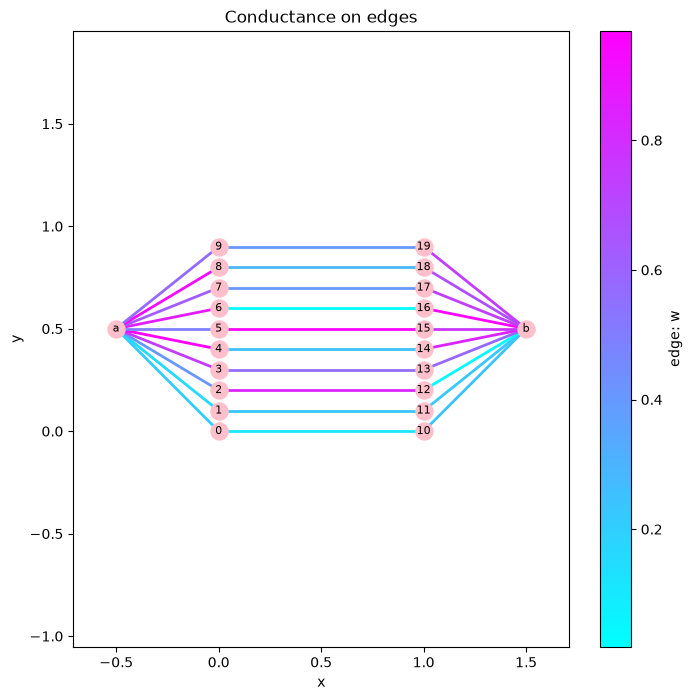

In [36]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Plot conductances - edge width proportional to conductance

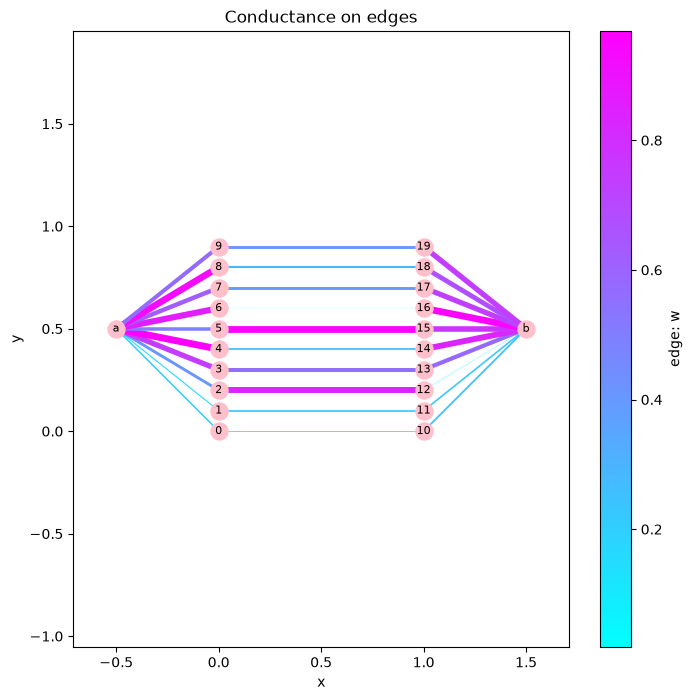

In [37]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')
plt.show()

## Flow in the network with boundary condition
Boundary nodes:
- $\mathcal{B} = \mathcal{B}_1 \sqcup \mathcal{B}_2$, with 
    - $p(u) = 1.0$ for $u\in\mathcal{B}_1$, node at the left of the domain
    - $p(u) = 0.0$ for $u\in\mathcal{B}_2$, node at the right of the domain

Inner nodes:
- $\mathcal{I}= V\setminus \mathcal{B}$, with $q(u)$ = 0 for $u\in\mathcal{I}$.


In [38]:
# Boundary nodes label
B1_nodes_label = ['a'] 
B2_nodes_label = ['b'] 
# B_nodes_label = B1_nodes_label + B2_nodes_label

# Potential at boundary nodes
pB1_nodes_dict = {u: 1.0 for u in B1_nodes_label}
pB2_nodes_dict = {u: 0.0 for u in B2_nodes_label}
# - merge dictionaries
pB_nodes_dict = pB1_nodes_dict
pB_nodes_dict.update(pB2_nodes_dict)

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pB_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pB_nodes_dict=pB_nodes_dict, 
                                qI_nodes_dict=qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)

# Set node potential as node attribute in graph `g`
nx.set_node_attributes(g, p_nodes_dict, 'potential')

# Add entering flux as node attribute 'entering_flux'
nx.set_node_attributes(g, q_nodes_dict, 'entering_flux')

# Absolute flows along edges
# --------------------------
# Compute absolute flows along edges
edge_abs_flow_dict = kn.tools.compute_abs_flow_along_edges(g, edge_weight='w', node_potential='potential')

# Set absolute flow as edge attribute in graph `g`
nx.set_edge_attributes(g, edge_abs_flow_dict, 'q_abs')

# Flows along edges - directed graph
# ----------------------------------
g_dir = kn.tools.compute_directed_graph_of_flow(g, edge_weight='w', node_potential='potential', edge_flow='q')
# -> directed graph with flow as edge attributes - only the edges with positive (or zero) flow are kept

### Do some checks

In [39]:
# Check local equation on each edge
ok = np.allclose(
    [g.edges[u, v]['q_abs'] - g.edges[u, v]['w'] * np.abs(g.nodes[u]['potential'] - g.nodes[v]['potential'])
        for u, v in g.edges()], 
    0)
print(f'Local equations ok ? {ok}')


Local equations ok ? True


In [40]:
# Check:
# - flux = 0 along edges linking 2 nodes in B1_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B1_nodes_label:
    for v in B1_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


In [41]:
# Check:
# - flux = 0 along edges linking 2 nodes in B2_nodes_label
d = nx.get_edge_attributes(g, 'q_abs')
for u in B2_nodes_label:
    for v in B2_nodes_label:
        if (u, v) in d.keys():
            print(f'edge: {u} ~ {v}, flux: {d[(u, v)]:.4g}')


In [42]:
# Check entering flux on boundary nodes
d = nx.get_node_attributes(g, 'entering_flux')

for u in B1_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

for u in B2_nodes_label:
    print(f'node: {u}, entering flux: {d[u]:.4g}')  

print()    

s = np.sum(list(d.values()))
print(f'sum of entering fluxes: {s:.4g}')
print(f'sum of entering fluxes close to zero ? {np.isclose(s, 0)}')


node: a, entering flux: 1.298

node: b, entering flux: -1.298

sum of entering fluxes: -4.441e-16
sum of entering fluxes close to zero ? True


### Plot result (1) - undirected graph
Plot node potential and absolute edge flow.

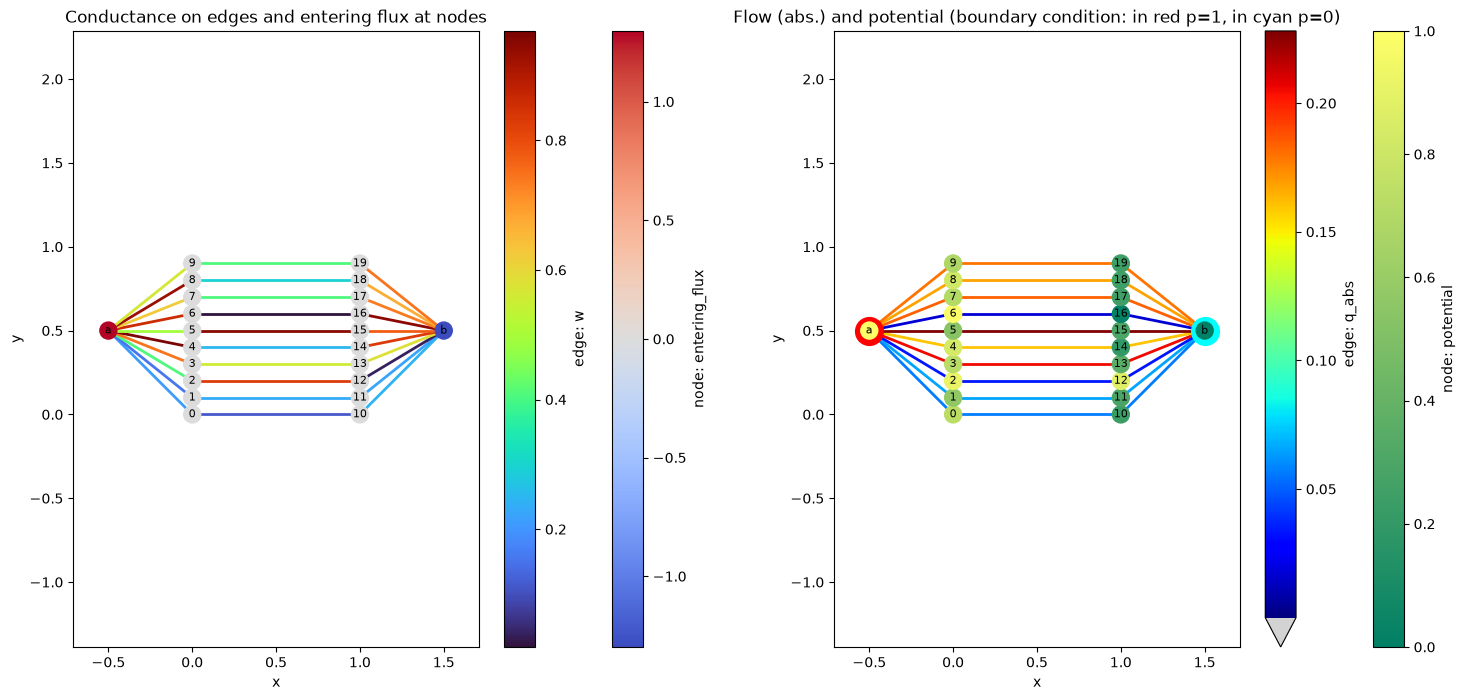

In [43]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'extend':'min'},
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


### Plot results (2) - directed graph

Plot node potential and oriented edge flow.

*Note. With directed graph, the color bar can not be displayed, because the function `nx.draw_networkx_edges` does not return any "mappable" required for plotting color bar. To display the color bar, one can first employ the undirected graph with absolute values of flow on edges, and then utilize the directed graph to show the oriented edges (see below).*

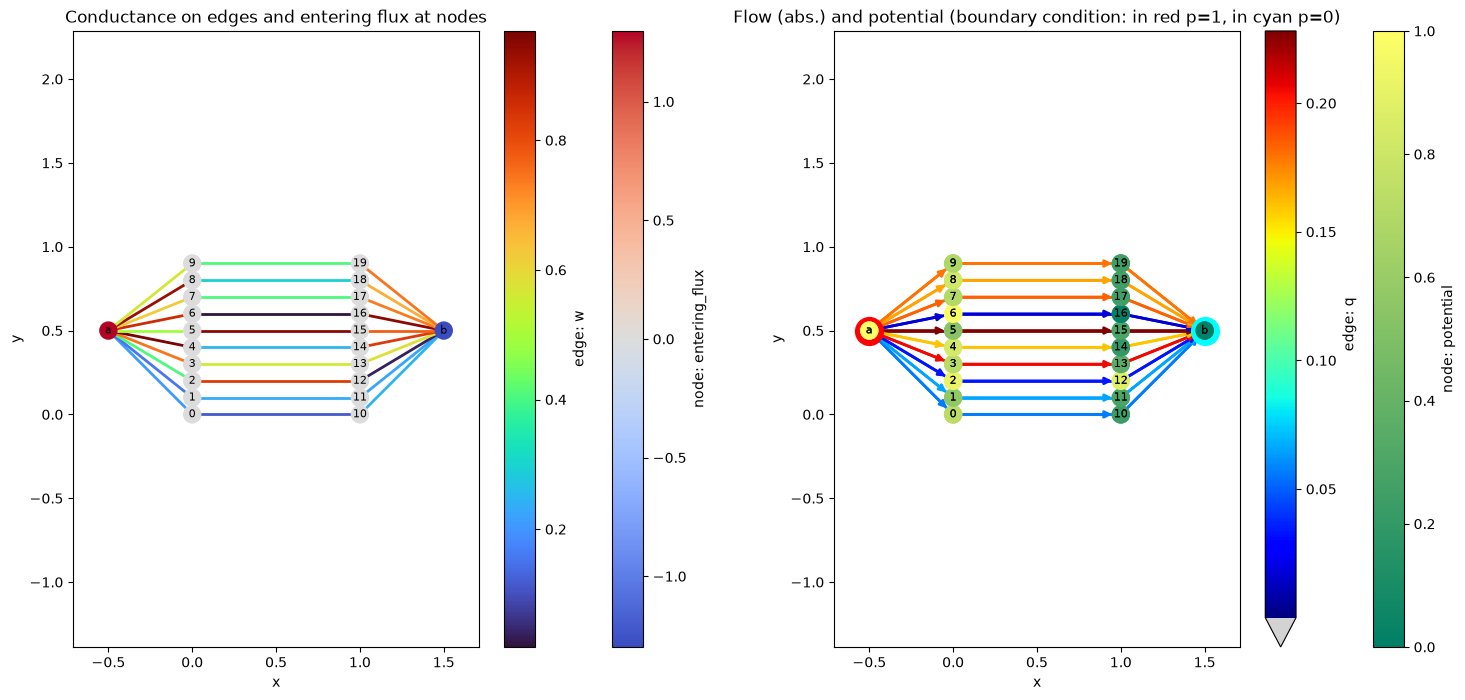

In [44]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ----
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    **options)
plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# ----------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    **options)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')
plt.show()


### Plot results (3) - directed graph - custom
Plot node potential and oriented edge flow ; set edge width according to values and add edge labels.

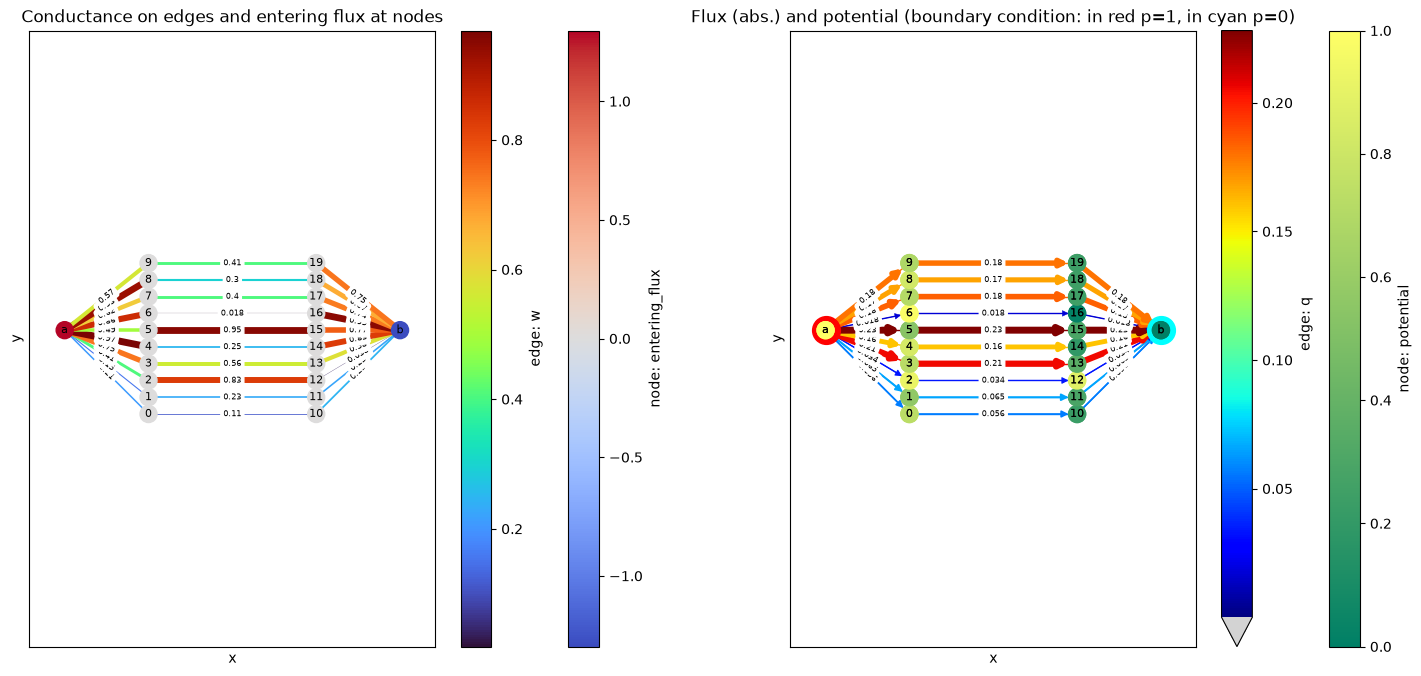

In [45]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

q = np.abs(np.asarray(list(nx.get_edge_attributes(g_dir, 'q').values())))
q_width_max = 5
q_width = q/q.max() * q_width_max

# Node position
pos = nx.get_node_attributes(g, 'pos')

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot - entering flux at nodes and conductance on edges
# ------------------------------------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr='entering_flux', cmap='coolwarm',
    edge_attr='w', edge_cmap='turbo',
    width = w_width, # set edge  width
    **options)

# ... add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'w').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

plt.title('Conductance on edges and entering flux at nodes')

# Plot - potential on nodes and absolute flow on edges
# --------------------------------------------------
# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10

plt.subplot(1,2,2)

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    width = q_width, # set edge  width
    **options)

# ...add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'q_abs').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

# ... highlight boundary nodes
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B1_nodes_label]).T, marker='o', s=400, color='red',  alpha=1)
plt.scatter(*np.asarray([g.nodes[u]['pos'] for u in B2_nodes_label]).T, marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flux (abs.) and potential (boundary condition: in red p=1, in cyan p=0)')

plt.show()


### Upscale the conductances in parallel

In [46]:
# Upscale the conductances
u0 = 'a'
u1 = 'b'
T_eq_1 = kn.tools.equivalent_conductance(g, [(u0, u1)], edge_weight='w')[0]
T_eq_2 = np.sum([1./(1.0/g[u0][i]['w'] + 1.0/g[i][n+i]['w'] + 1.0/g[n+i][u1]['w']) for i in range(n)])
print(f'Equivalent conductance in parallel is the sum of the single conductances : {np.isclose(T_eq_1, T_eq_2)}')
# Here, single conductances are the conductance in series u0 -> i -> i+n -> u1


Equivalent conductance in parallel is the sum of the single conductances : True
